In [1]:
import pandas as pd
df = pd.read_csv("train.csv")
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [2]:
print("dataset shape:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\ndataset information:")
df.info()

dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [3]:
print("missing values in each column:")
print(df.isnull().sum())

missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
df_clean = df.copy()
df_clean["Age"]=df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Embarked"]=df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
df_clean = df_clean.drop(columns=["Cabin"])
print(df_clean.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [7]:
print("duplicate rows before removal:",df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("duplicate rows before removal:",df_clean.duplicated().sum())

duplicate rows before removal: 0
duplicate rows before removal: 0


In [8]:
print("sex categories:")
print(df_clean["Sex"].value_counts())
print("\nEmbarked categories:")
print(df_clean["Embarked"].value_counts())
print("\nPassenger classes:")
print(df_clean["Pclass"].value_counts())

sex categories:
Sex
male      577
female    314
Name: count, dtype: int64

Embarked categories:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

Passenger classes:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64


In [9]:
print("data before conversion:")
print(df_clean.dtypes)

data before conversion:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object


In [10]:
print(df_clean.isnull().sum().sum())

0


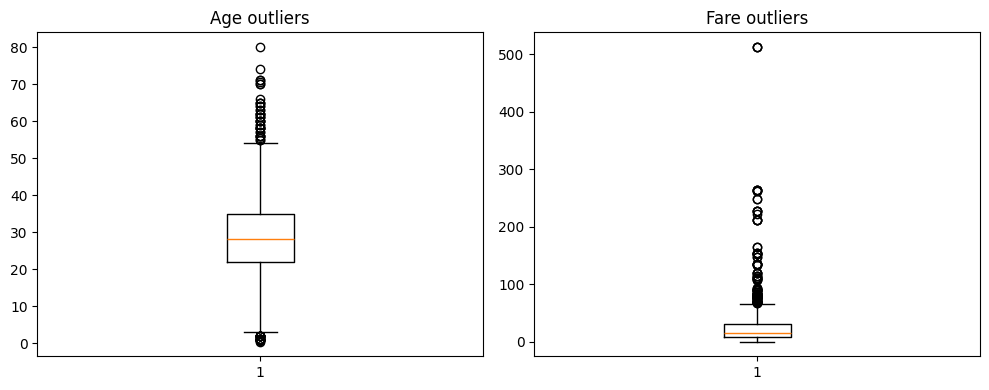

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.boxplot(df_clean["Age"])
plt.title("Age outliers")
plt.subplot(1,2,2)
plt.boxplot(df_clean["Fare"])
plt.title("Fare outliers")
plt.tight_layout()
plt.show()


In [13]:
Q1 = df_clean[["Age","Fare"]].quantile(0.25)
Q3 = df_clean[["Age","Fare"]].quantile(0.75)
IQR = Q3 - Q1
lower = Q1-1.5*IQR
upper = Q3 + 1.5*IQR
print("lower limits:")
print(lower)
print("\nUpper limits:")
print(upper)
print("\nNumber of outliers:")
print(((df_clean[["Age","Fare"]]<lower)|(df_clean[["Age","Fare"]]>upper)).sum())

lower limits:
Age      2.500
Fare   -26.724
dtype: float64

Upper limits:
Age     54.5000
Fare    65.6344
dtype: float64

Number of outliers:
Age      66
Fare    116
dtype: int64


In [15]:
df_clean["FamilySize"] = df_clean["SibSp"]+ df_clean["Parch"]+1
df_clean["IsAlone"] = (df_clean["FamilySize"]==1).astype(int)
print(df_clean[["SibSp","Parch","FamilySize","IsAlone"]].head(10))


   SibSp  Parch  FamilySize  IsAlone
0      1      0           2        0
1      1      0           2        0
2      0      0           1        1
3      1      0           2        0
4      0      0           1        1
5      0      0           1        1
6      0      0           1        1
7      3      1           5        0
8      0      2           3        0
9      1      0           2        0


In [16]:
print("Dataset Shape:", df_clean.shape)
print("\nMissing Values:")
print(df_clean.isnull().sum().sum())
print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())
print("\nFinal Columns:")
print(df_clean.columns.tolist())

Dataset Shape: (891, 13)

Missing Values:
0

Duplicate Rows:
0

Final Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']


In [17]:
df_clean.to_csv("cleaned_titanic.csv",index=False)
print("cleaned dataset saved successfully!")

cleaned dataset saved successfully!


In [18]:
from google.colab import files
files.download("cleaned_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
df_encoded = df_clean.copy()
df_encoded["Sex"] = df_encoded["Sex"].map({"male":0,"female":1})
df_encoded= pd.get_dummies(
    df_encoded,
    columns=["Embarked"],
    dtype=int
)
print(df_encoded.head())
print("Encoding completed!")

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    0  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    1  38.0      1      0   
2                             Heikkinen, Miss. Laina    1  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    1  35.0      1      0   
4                           Allen, Mr. William Henry    0  35.0      0      0   

             Ticket     Fare  FamilySize  IsAlone  Embarked_C  Embarked_Q  \
0         A/5 21171   7.2500           2        0           0           0   
1          PC 17599  71.2833           2        0           1           0   
2  STON/O2. 3101282   7.9250           1        1           0    

In [20]:
from sklearn.preprocessing import StandardScaler
df_scaled = df_encoded.copy()
scaler = StandardScaler()
df_scaled[["Age","Fare"]]= scaler.fit_transform(df_scaled[["Age","Fare"]]
)
print(df_scaled[["Age","Fare"]].head())
print("\nScaling completed syuccessfully!")

        Age      Fare
0 -0.565736 -0.502445
1  0.663861  0.786845
2 -0.258337 -0.488854
3  0.433312  0.420730
4  0.433312 -0.486337

Scaling completed syuccessfully!


In [21]:
print("final dataset shape:",df_scaled.shape)
print("\nMissing values:")
print(df_scaled.isnull().sum().sum())
print("\nDuplicate Rows:")
print(df_scaled.duplicated().sum().sum())
print("\nFinal coumns:")
print(df_scaled.columns.tolist())

final dataset shape: (891, 15)

Missing values:
0

Duplicate Rows:
0

Final coumns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'FamilySize', 'IsAlone', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [22]:
df_scaled.to_csv("Final_cleaned_titanic.csv",index=False)
print("Final saved successfully!")


Final saved successfully!


In [25]:
from google.colab import files
files.download("Final_cleaned_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
df_final=df_clean.copy()
for col in["Age","Fare"]:
  Q1=df_final[col].quantile(0.25)
  Q3=df_final[col].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-1.5*IQR
  upper=Q3+1.5*IQR
  df_final[col]=df_final[col].clip(
      lower=lower,
      upper=upper
  )
  print("Outliers handled successfully!")
  print(df_final[["Age","Fare"]].describe())

Outliers handled successfully!
              Age        Fare
count  891.000000  891.000000
mean    29.039282   32.204208
std     12.072074   49.693429
min      2.500000    0.000000
25%     22.000000    7.910400
50%     28.000000   14.454200
75%     35.000000   31.000000
max     54.500000  512.329200
Outliers handled successfully!
              Age        Fare
count  891.000000  891.000000
mean    29.039282   24.046813
std     12.072074   20.481625
min      2.500000    0.000000
25%     22.000000    7.910400
50%     28.000000   14.454200
75%     35.000000   31.000000
max     54.500000   65.634400


In [29]:
print("Age minimum:",df_final["Age"].min())
print("Age maximum:",df_final["Age"].max())
print("Fare minimum:", df_final["Fare"].min())
print("Fare maximum:",df_final["Fare"].max())

Age minimum: 2.5
Age maximum: 54.5
Fare minimum: 0.0
Fare maximum: 65.6344


In [30]:
print(df_final[["Age","Fare"]].describe())

              Age        Fare
count  891.000000  891.000000
mean    29.039282   24.046813
std     12.072074   20.481625
min      2.500000    0.000000
25%     22.000000    7.910400
50%     28.000000   14.454200
75%     35.000000   31.000000
max     54.500000   65.634400


In [32]:
df_final.to_csv("final_final_cleaned_titanic.csv",index=False)


In [33]:
from google.colab import files
files.download("final_final_cleaned_titanic.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>